# 电–热–气–氢综合能源系统优化调度与容量配置 —— 论文复现

> Wang J, Liu H, Xu C. Resource scheduling and capacity allocation optimization of an integrated electricity-heat-gas-hydrogen energy system. *Energy*, 2025, 337: 138683. https://doi.org/10.1016/j.energy.2025.138683

模型代码全部在 `ies_model.py` 中，本 notebook 只负责调用、展示结果并与论文对比。
默认参数复现论文报告的结果，与论文公式字面写法不同的三处见 README 的“复现说明”。

In [1]:
import pandas as pd
import ies_model as M

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 50)
%matplotlib inline

## 1. 第 4 节：24 h 优化调度

默认口径：储能按论文作者的实现（`mode="paper"`，S_n(1)=0），富余碳配额按 2λ 出售，转换设备运维成本按 α × 容量计。

In [2]:
res = M.solve(M.Params(), mode="paper")
M.print_report(res)

调度总成本 / ¥: 802,758.9
  外购能源成本 CEP / ¥: 949,714.5
  运维成本 COP / ¥: 244,355.7
  阶梯碳交易成本 CCT / ¥: -391,711.9
  弃风弃光惩罚 CWS / ¥: 0.0
  碳封存成本 CCS / ¥: 400.6
  CO2 产生量 / t: 440.96
  CO2 排放量 / t: 154.33
  CCS 耗电 / MWh: 77.10
  CCS 运维成本 / ¥: 4,240.56
  参与交易净排放 / t: -783.42
  弃风弃光 / MWh: 0.00
  ΔS1 电储能 S(1)−S(T): -179.86
  ΔS2 热储能 S(1)−S(T): -40.00
  ΔS3 气储能 S(1)−S(T): -20.00
  ΔS4 氢储能 S(1)−S(T): -200.00


In [3]:
M.compare_with_paper(res)

,本模型,论文,相对偏差 %
指标,,,
总成本,"802,758.94","847,510.40",-5.28
外购能源成本 CEP,"949,714.53","907,654.70",4.63
运维成本 COP,"244,355.74","271,766.20",-10.09
碳交易成本 CCT,"-391,711.90","-341,820.20",-14.60
弃风弃光成本 CWS,0.00,"9,558.50",-100.00
碳封存成本 CCS,400.56,351.10,14.09
CO2 产生量 / t,440.96,386.83,13.99
CO2 排放量 / t,154.33,135.39,13.99
CCS 耗电 / MWh,77.10,67.00,15.08


### 能量平衡与碳流图（对应论文 Fig.4(a)–(f)）

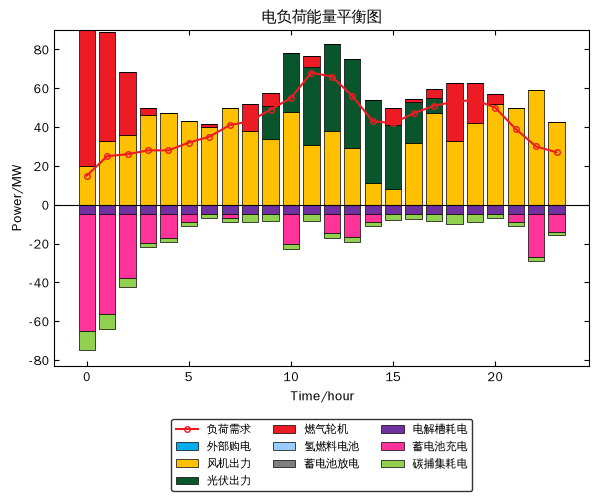

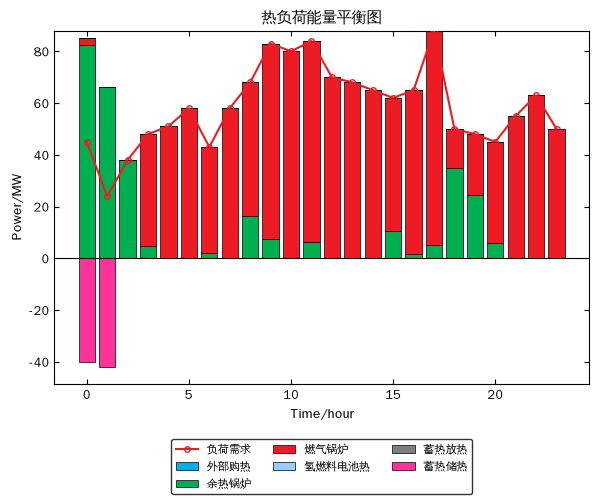

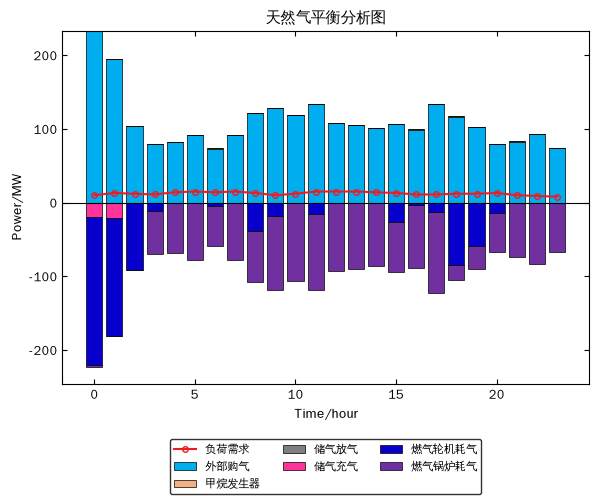

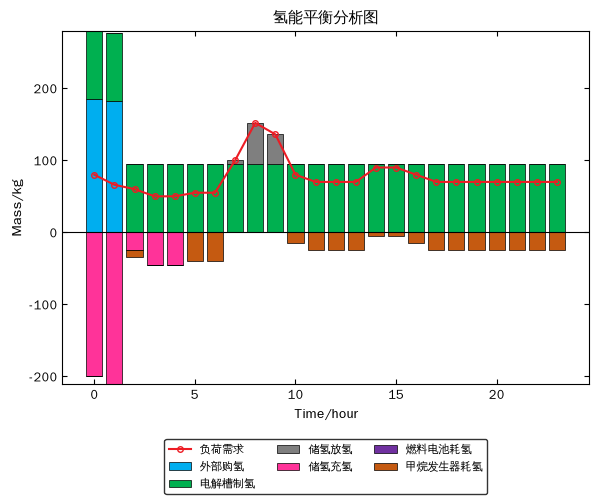

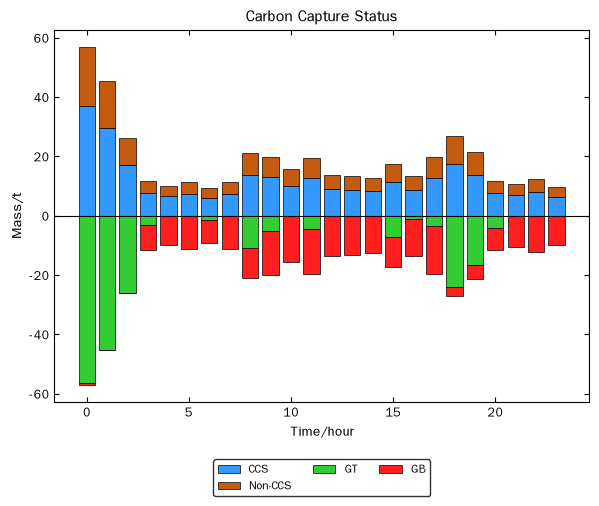

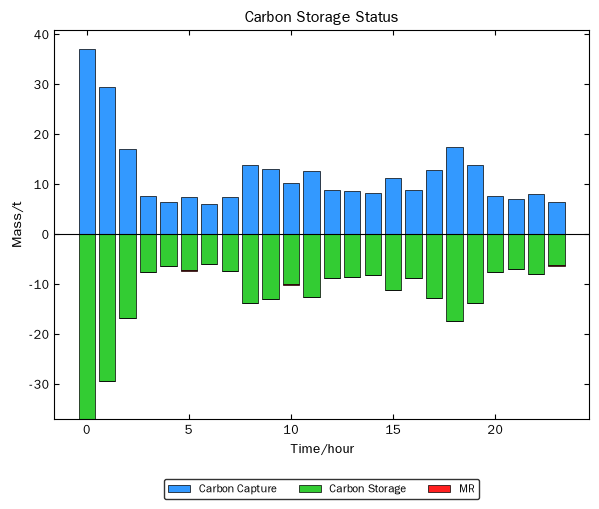

In [4]:
figs = M.plot_all(res.df)

### 逐时调度结果

In [5]:
cols = ["E_Buy", "WT", "WT_cut", "PV", "GT_e", "EL_e", "CCS_e", "ES1_cha", "ES1_dis", "SOC1",
        "WHB_h", "GB_h", "ES2_cha", "SOC2", "G_Buy", "MR_g", "H2_Buy", "EL_H2", "MR_H2", "ES4_cha", "ES4_dis", "SOC4"]
res.df.set_index("t")[cols].round(2)

,E_Buy,WT,WT_cut,PV,GT_e,EL_e,CCS_e,ES1_cha,ES1_dis,SOC1,WHB_h,GB_h,ES2_cha,SOC2,G_Buy,MR_g,H2_Buy,EL_H2,MR_H2,ES4_cha,ES4_dis,SOC4
t,,,,,,,,,,,,,,,,,,,,,,
0,0.00,20.00,0.00,0.00,69.96,5.00,9.97,59.99,0.00,0.00,82.45,2.55,40.00,0.00,233.28,0.00,185.16,94.84,0.00,200.00,0.00,0.00
1,0.00,33.00,0.00,0.00,56.09,5.00,7.92,51.17,0.00,48.61,66.11,0.00,42.11,40.00,194.31,0.00,181.69,94.84,0.00,210.53,0.00,200.00
2,0.00,36.00,0.00,0.00,32.24,5.00,4.55,32.69,0.00,79.61,38.00,0.00,0.00,40.00,103.89,0.23,0.00,94.84,9.86,24.98,0.00,223.73
3,0.00,46.00,0.00,0.00,3.99,5.00,2.04,14.95,0.00,93.74,4.71,43.29,0.00,40.00,80.13,0.00,0.00,94.84,0.00,44.84,0.00,266.33
4,0.00,47.00,0.00,0.00,0.00,5.00,1.74,12.26,0.00,105.29,0.00,51.00,0.00,40.00,82.00,0.00,0.00,94.84,0.00,44.84,0.00,308.92
5,0.00,43.00,0.00,0.00,0.00,5.00,1.98,4.02,0.00,109.01,0.00,58.00,0.00,40.00,91.39,0.95,0.00,94.84,39.84,0.00,0.00,308.92
6,0.00,40.00,0.00,0.00,1.63,5.00,1.63,0.00,0.00,108.90,1.92,41.08,0.00,40.00,72.49,0.95,0.00,94.84,39.84,0.00,0.00,308.92
7,0.00,50.00,0.00,0.00,0.00,5.00,1.98,2.02,0.00,110.71,0.00,58.00,0.00,40.00,92.33,0.00,0.00,94.84,0.00,0.00,5.16,303.49
8,0.00,38.00,0.00,0.00,13.70,5.00,3.70,0.00,0.00,110.60,16.15,51.85,0.00,40.00,121.29,0.00,0.00,94.84,0.00,0.00,57.16,243.33


## 2. 不同口径的对比

- `paper`：论文作者的储能实现（第 1 时段的强制充电不计入库存，第 2 时段充到下限）
- `zero_start`：物理上自洽的写法（调度开始前库存为 0，第 1 时段的充电计入库存）
- `cyclic`：日内循环（首末库存相等）
- `literal`：按论文公式字面实现（富余配额按 λ 出售、运维成本按出力计），储能用 `paper` 口径

In [6]:
rows = {}
for name, p, mode in [("paper（默认）", M.Params(), "paper"),
                      ("zero_start", M.Params(), "zero_start"),
                      ("cyclic", M.Params(), "cyclic"),
                      ("literal", M.Params.literal(), "paper")]:
    rows[name] = M.compare_with_paper(M.solve(p, mode))["本模型"]
table = pd.DataFrame(rows)
table["论文"] = pd.Series(M.PAPER_RESULTS)
table

,paper（默认）,zero_start,cyclic,literal,论文
指标,,,,,
总成本,"802,758.94","773,397.32","753,042.22","948,882.46","847,510.40"
外购能源成本 CEP,"949,714.53","882,989.91","757,987.63","881,107.58","907,654.70"
运维成本 COP,"244,355.74","238,663.75","232,583.04","221,231.66","271,766.20"
碳交易成本 CCT,"-391,711.90","-348,613.89","-239,353.88","-153,774.80","-341,820.20"
弃风弃光成本 CWS,0.00,0.00,"1,576.19",0.00,"9,558.50"
碳封存成本 CCS,400.56,357.56,249.23,318.02,351.10
CO2 产生量 / t,440.96,393.76,274.75,349.63,386.83
CO2 排放量 / t,154.33,137.82,96.16,122.37,135.39
CCS 耗电 / MWh,77.10,68.85,48.04,61.13,67.00


## 3. 第 5 节：容量配置

### 3.1 论文优化容量下的成本变化（Table 4、Table 6）

论文与本模型的基准成本不同，这里比较各容量方案相对各自基准的降幅。

In [7]:
M.section5_comparison()

,本模型总成本,本模型降幅 %,论文总成本,论文降幅 %
容量方案,,,,
GT = 254.126,"798,685.51",-0.51,"843,440.00",-0.48
EL = 60.6105,"539,268.92",-32.82,"570,690.00",-32.66
MR = 72.7329,"785,195.49",-2.19,"830,750.00",-1.98
HFC = 0,"802,308.94",-0.06,"847,060.00",-0.05
GB = 81.7263,"724,977.30",-9.69,"770,170.00",-9.13
WHB = 81.2426,"769,101.71",-4.19,"813,800.00",-3.98
Table 6 六设备,"415,851.33",-48.20,"446,106.70",-47.36


### 3.2 单设备容量与总成本的关系（对应论文 Fig.5）

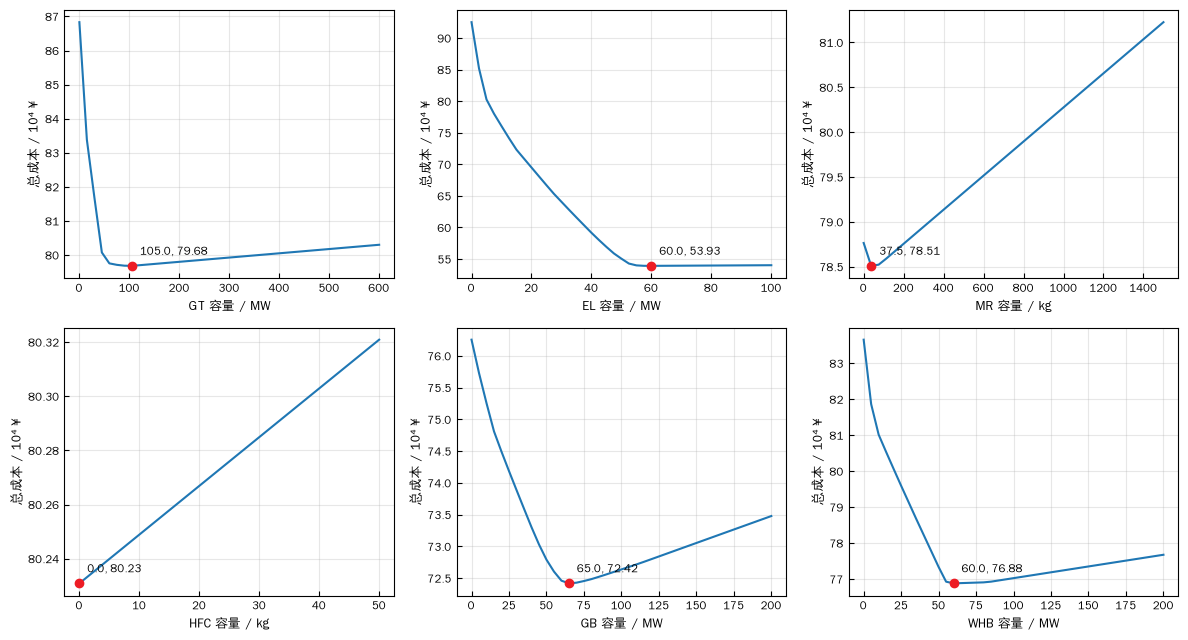

In [8]:
import numpy as np

ranges = {"GT": (0, 600), "EL": (0, 100), "MR": (0, 1500), "HFC": (0, 50), "GB": (0, 200), "WHB": (0, 200)}
sweeps = {dev: M.capacity_sweep(dev, np.linspace(lo, hi, 41)) for dev, (lo, hi) in ranges.items()}
fig = M.plot_sweeps(sweeps)

### 3.3 单设备容量寻优（对应论文 Table 4）

一维问题用逐级加密的网格搜索求最优容量（论文用 PSO/GA，结果一致）。

In [9]:
rows = []
for dev, (lo, hi) in ranges.items():
    cap, cost = M.optimize_single(dev, (lo, hi))
    paper_cap, paper_cost = M.PAPER_TABLE4[dev]
    rows.append((dev, cap, cost, paper_cap, paper_cost))
pd.DataFrame(rows, columns=["设备", "本模型最优容量", "本模型总成本", "论文最优容量", "论文总成本"]).set_index("设备")

,本模型最优容量,本模型总成本,论文最优容量,论文总成本
设备,,,,
GT,102.00,"796,790.10",254.13,"843,440.00"
EL,59.90,"539,251.15",60.61,"570,690.00"
MR,50.00,"784,908.33",72.73,"830,750.00"
HFC,0.00,"802,308.94",0.00,"847,060.00"
GB,65.13,"724,183.69",81.73,"770,170.00"
WHB,56.27,"768,760.01",81.24,"813,800.00"


### 3.4 六设备容量同时寻优（PSO，对应论文 Table 6）

每个粒子的适应度就是该容量组合下第 4 节调度模型的最优总成本。30 个粒子、60 代，约 1–3 分钟。

In [10]:
bounds = {"GT": (0, 600), "EL": (0, 100), "MR": (0, 2000), "HFC": (0, 50), "GB": (0, 200), "WHB": (0, 200)}
best_caps, best_cost, history = M.pso_capacities(bounds, n_particles=30, iters=60, seed=0, verbose=False)
out = pd.DataFrame({"本模型 PSO": pd.Series(best_caps), "论文 Table 6": pd.Series(M.PAPER_OPT_CAPACITY)})
out.loc["总成本"] = [best_cost, M.PAPER_OPT_COST]
out

,本模型 PSO,论文 Table 6
PGT_max,105.18,162.83
PEL_max,62.37,65.51
HMR_max,"1,047.23","1,127.20"
HHFC_max,0.00,0.00
PGB_max,0.00,0.00
PWHB_max,85.00,87.97
总成本,"415,258.22","446,106.70"


调度总成本 / ¥: 415,258.2
  外购能源成本 CEP / ¥: 1,218,703.3
  运维成本 COP / ¥: 125,329.4
  阶梯碳交易成本 CCT / ¥: -929,668.7
  弃风弃光惩罚 CWS / ¥: 0.0
  碳封存成本 CCS / ¥: 894.3
  CO2 产生量 / t: 1,024.74
  CO2 排放量 / t: 358.66
  CCS 耗电 / MWh: 179.17
  CCS 运维成本 / ¥: 9,854.62
  参与交易净排放 / t: -1,859.34
  弃风弃光 / MWh: 0.00
  ΔS1 电储能 S(1)−S(T): -39.97
  ΔS2 热储能 S(1)−S(T): -40.00
  ΔS3 气储能 S(1)−S(T): -20.00
  ΔS4 氢储能 S(1)−S(T): -200.00


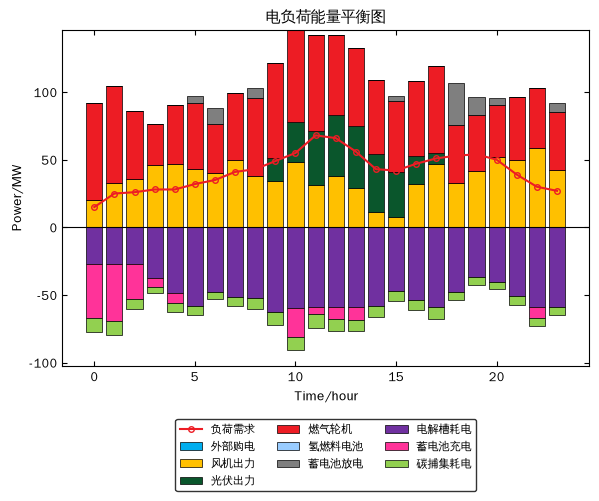

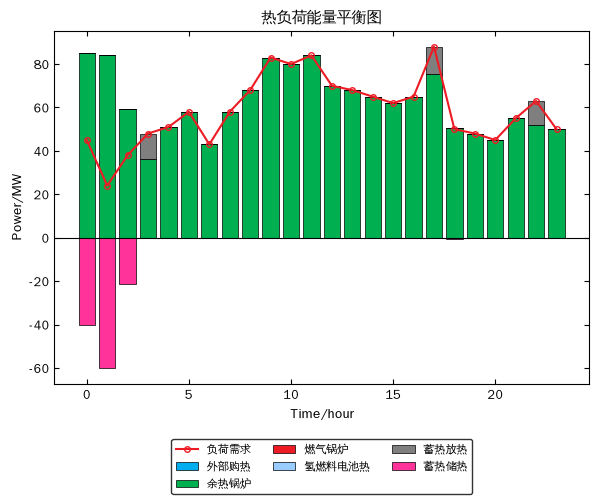

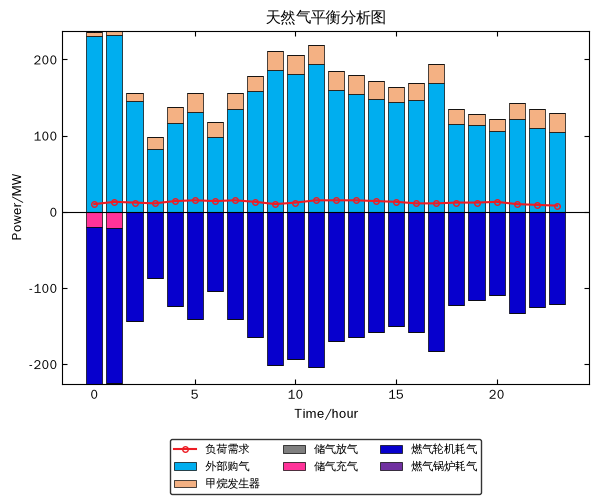

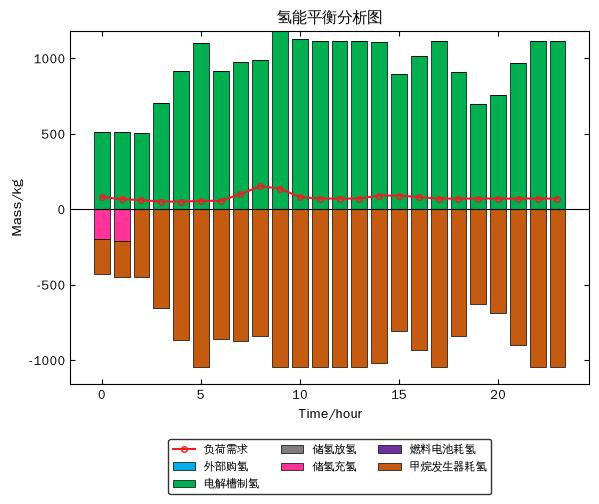

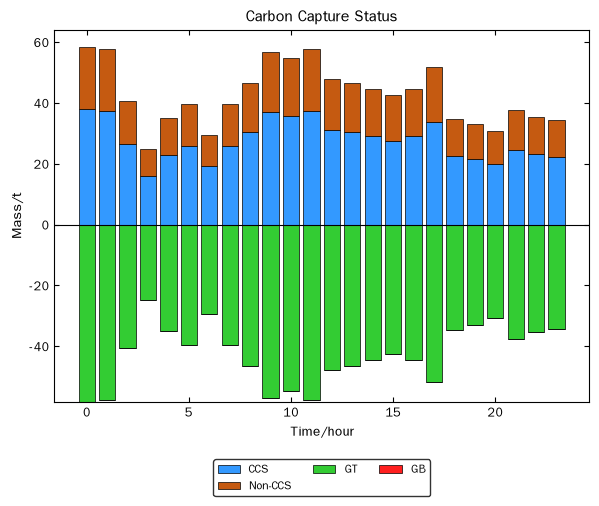

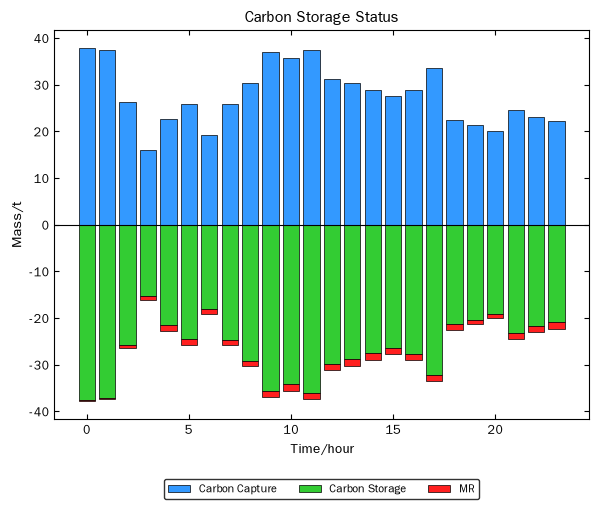

In [11]:
res_opt = M.solve(M.with_capacities(M.Params(), **best_caps))
M.print_report(res_opt)
figs_opt = M.plot_all(res_opt.df)